In [2]:
import io

import matplotlib.pyplot as plt
import pandas as pd
import plotly.express as px
import aggregated_use_cases_analysis.visualization as visualization
import aggregated_use_cases_analysis.transform.hopt as transform_hopt
from pathlib import Path
import seaborn as sns

sns.set_style("darkgrid")

%load_ext autoreload
%autoreload 2

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [4]:
path_experiments = Path("/beegfs/ws/0/s4610340-isml/lrl_sorb/experiments")
experiments = [
    {
        "name": "001_lrl_sorb_hopt_tl_tpe_adamw_hf_seeds",
        "dataset+model": "lrl_sorb(Czech->csb)",
    },
    {
        "name": "002_lrl_sorb_hopt_tl_tpe_paged_adamw_32bit_seeds",
        "dataset+model": "lrl_sorb(Czech->csb)"
    },
    {
        "name": "003_lrl_sorb_hopt_tl_tpe_paged_adamw_8bit_seeds",
        "dataset+model": "lrl_sorb(Czech->csb)"
    },
    {
        "name": "004_lrl_sorb_hopt_tl_tpe_paged_lion_32bit_seeds",
        "dataset+model": "lrl_sorb(Czech->csb)"
    },
    {
        "name": "005_lrl_sorb_hopt_tl_tpe_paged_lion_8bit_seeds",
        "dataset+model": "lrl_sorb(Czech->csb)"
    },
    {
        "name": "006_lrl_sorb_czech_hsb_hopt_tl_tpe_adamw_hf_seeds",
        "dataset+model": "lrl_sorb(Czech->hsb)"
    },
    {
        "name": "007_lrl_sorb_robeczech_csb_hopt_tl_tpe_adamw_hf_seeds",
        "dataset+model": "lrl_sorb(RobeCzech->csb)"
    },
]

for experiment in experiments:
    experiment["df"] = pd.read_csv(
        path_experiments / experiment["name"] / "data" / "processed" / "hopt" / "omniopt_results.csv",
        index_col=0
    )
    
experiments[0]["df"]

,time,0,BL,BO,BP,IO,IP,RESULT,endtime,hostname,learning_rate,logfile_path,loss,num_train_epochs,starttime,weight_decay,omniopt_seed
0,2023-09-07 15:27:16,0.0,80.0,56.0,49.0,88.0,53.0,1.000000,1.694100e+09,taurusi8003,0.001702,/beegfs/.global0/ws/s4610340-isml/lrl_sorb/exp...,1.000000,15.0,1.694100e+09,0.000092,857
1,2023-09-07 15:27:16,0.0,80.0,56.0,49.0,88.0,53.0,1.000000,1.694100e+09,taurusi8003,0.025889,/beegfs/.global0/ws/s4610340-isml/lrl_sorb/exp...,1.000000,15.0,1.694100e+09,0.000240,857
2,2023-09-07 15:27:16,0.0,80.0,56.0,49.0,88.0,53.0,1.000000,1.694100e+09,taurusi8003,0.011710,/beegfs/.global0/ws/s4610340-isml/lrl_sorb/exp...,1.000000,19.0,1.694100e+09,0.000078,857
3,2023-09-07 15:27:16,0.0,80.0,56.0,49.0,88.0,53.0,0.424242,1.694100e+09,taurusi8003,0.000056,/beegfs/.global0/ws/s4610340-isml/lrl_sorb/exp...,0.424242,10.0,1.694100e+09,0.028587,857
4,2023-09-07 15:27:16,0.0,80.0,56.0,49.0,88.0,53.0,1.000000,1.694100e+09,taurusi8003,0.133285,/beegfs/.global0/ws/s4610340-isml/lrl_sorb/exp...,1.000000,11.0,1.694100e+09,0.006046,857
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
244,2023-09-07 17:03:25,0.0,80.0,56.0,49.0,88.0,53.0,1.000000,1.694106e+09,taurusi8028,0.072733,/beegfs/.global0/ws/s4610340-isml/lrl_sorb/exp...,1.000000,15.0,1.694106e+09,0.000593,703
245,2023-09-07 17:03:57,0.0,80.0,56.0,49.0,88.0,53.0,1.000000,1.694106e+09,taurusi8028,0.002739,/beegfs/.global0/ws/s4610340-isml/lrl_sorb/exp...,1.000000,15.0,1.694106e+09,0.000104,703
246,2023-09-07 17:03:57,0.0,80.0,56.0,49.0,88.0,53.0,1.000000,1.694106e+09,taurusi8028,0.000973,/beegfs/.global0/ws/s4610340-isml/lrl_sorb/exp...,1.000000,16.0,1.694106e+09,0.000276,703
247,2023-09-07 17:04:01,0.0,80.0,56.0,49.0,88.0,53.0,1.000000,1.694106e+09,taurusi8028,0.005934,/beegfs/.global0/ws/s4610340-isml/lrl_sorb/exp...,1.000000,11.0,1.694106e+09,0.000073,703


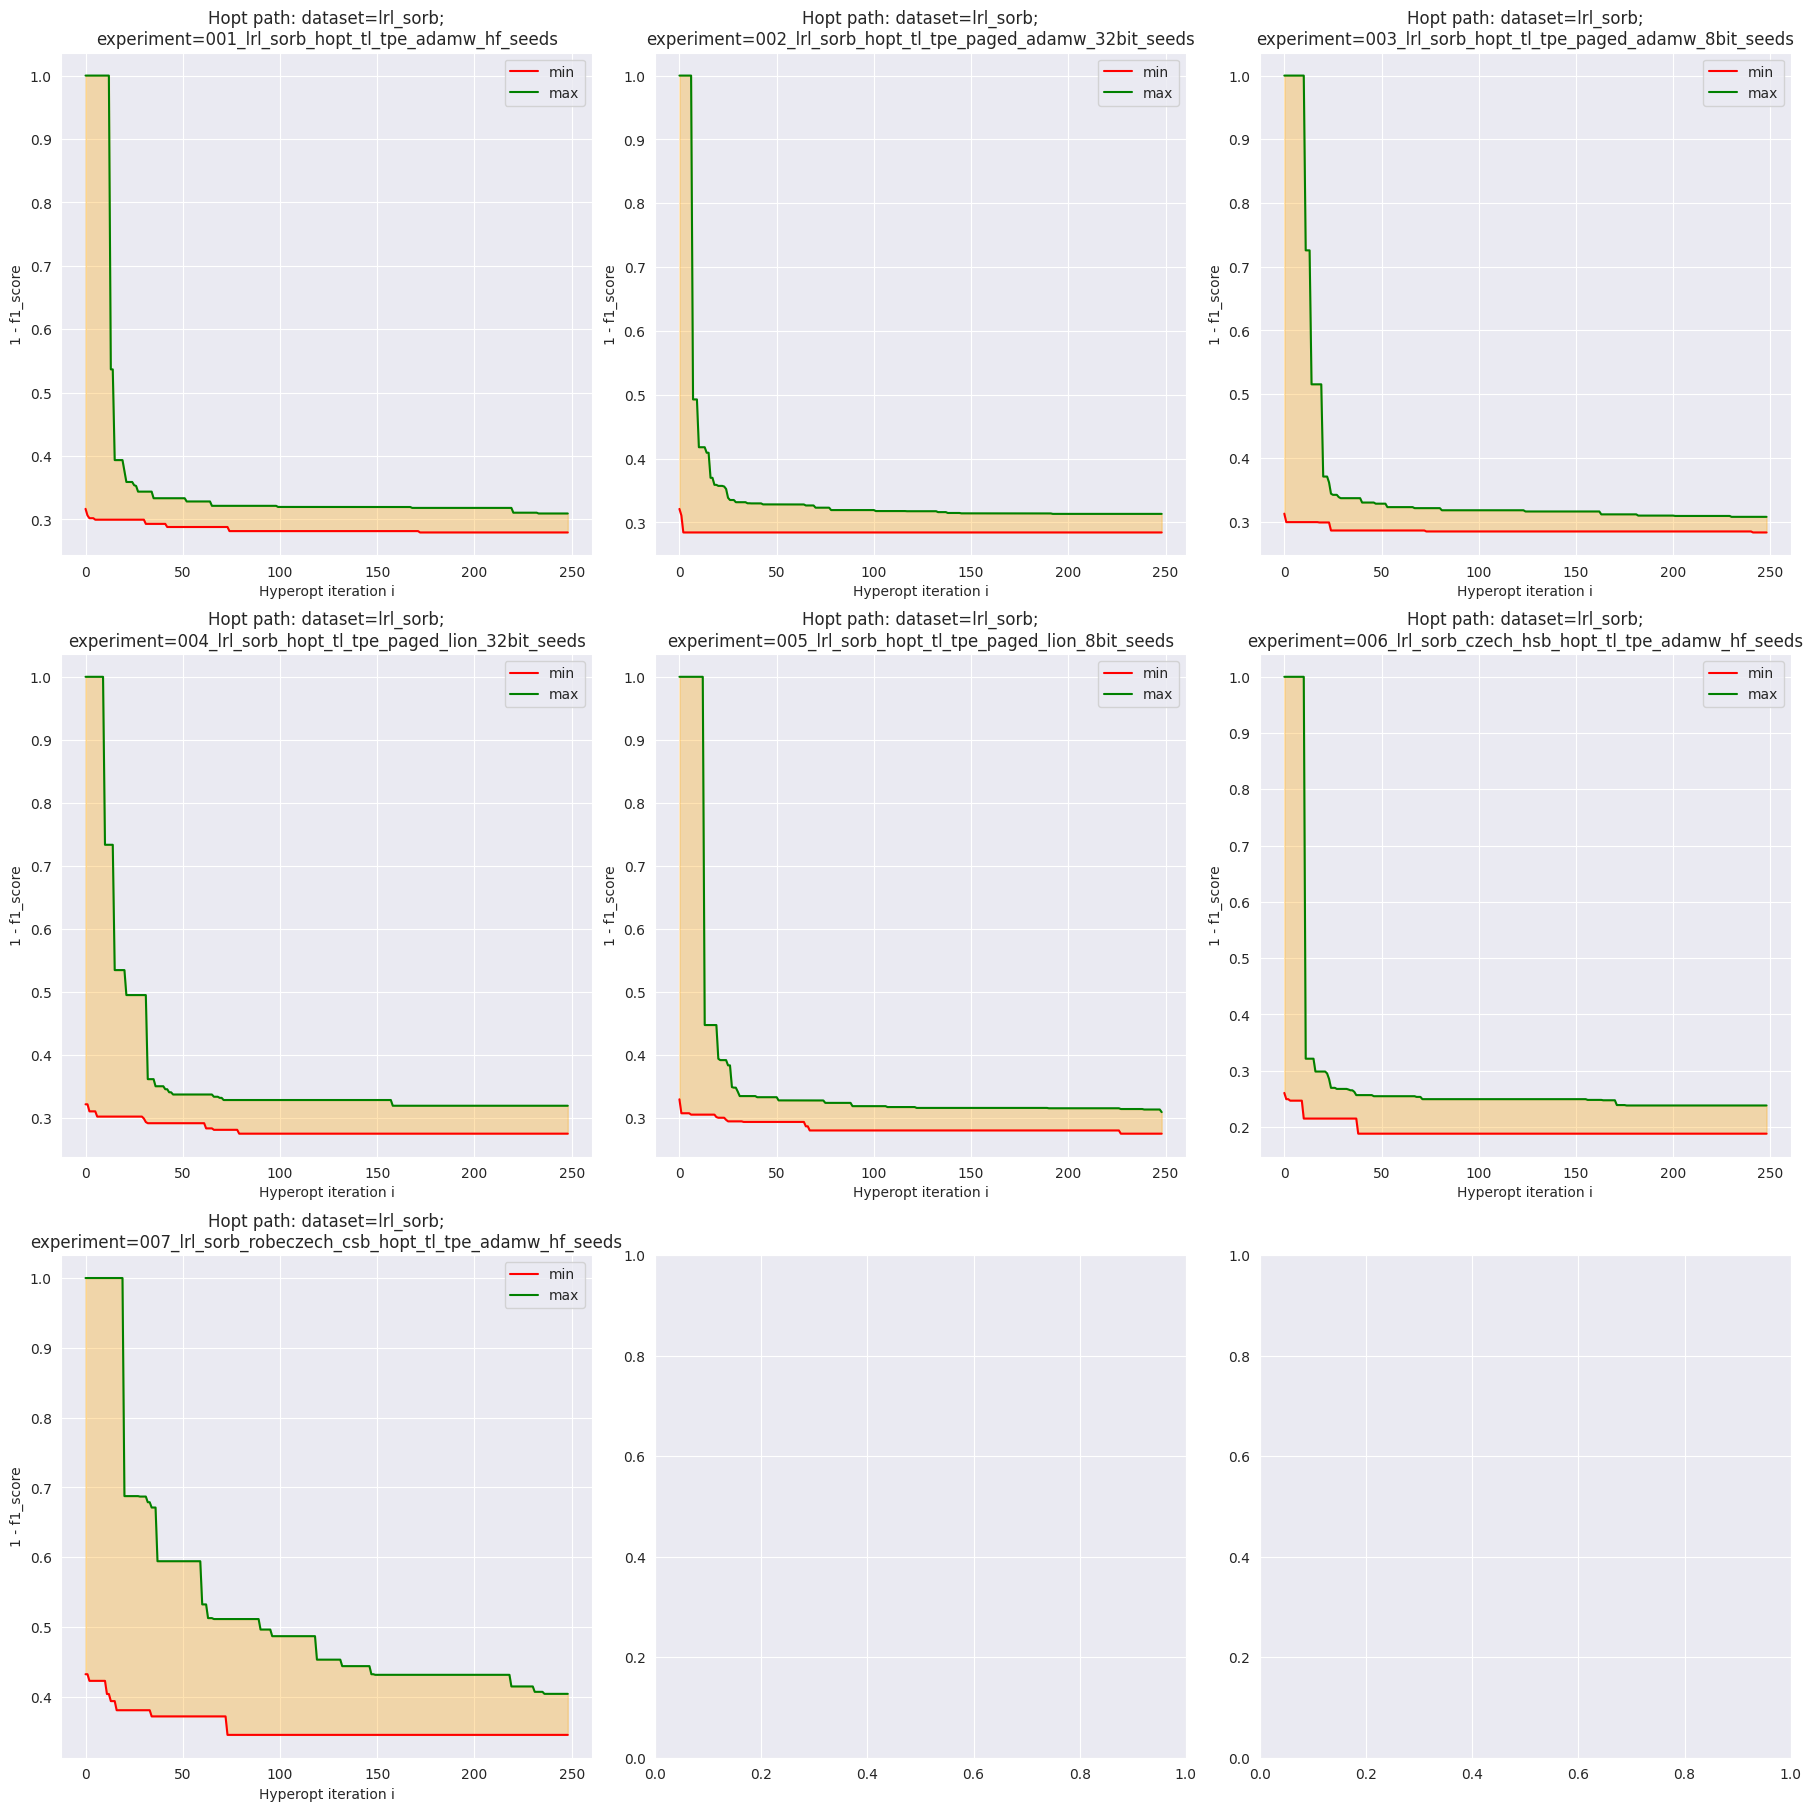

In [6]:
fig: plt.Figure

ncols = 3
nrows = len(experiments) // 3 + 1

fig, axs = plt.subplots(ncols=ncols, nrows=nrows, figsize=(ncols*6, nrows*6), constrained_layout=True)
axs = axs.flatten()

for i, experiment in enumerate(experiments):
    visualization.hopt_results_plot.plot_opt_iterations(
        df=experiment["df"],
        experiment_name=experiment["name"],
        dataset_name="lrl_sorb",
        hopt_algorithm_name="tpe.suggest",
        metric_name="1 - f1_score",
        result_col="RESULT",
        title_pre="Hopt path",
        ax=axs[i]
    )


In [7]:
for experiment in experiments:
    experiment["df_minima_latest"] = transform_hopt.extract_latest_minima_from_hopt_df(experiment["df"], result_col="RESULT")

experiment["df_minima_latest"]

,time,0,BL,BO,BP,IO,IP,RESULT,endtime,hostname,learning_rate,logfile_path,loss,num_train_epochs,starttime,weight_decay,omniopt_seed
omniopt_seed,,,,,,,,,,,,,,,,,
38,2023-09-17 15:01:09,0.0,80.0,56.0,49.0,88.0,53.0,0.367089,1.694963e+09,taurusi8005,0.000069,/beegfs/.global0/ws/s4610340-isml/lrl_sorb/exp...,0.367089,19.0,1.694963e+09,0.001566,38
56,2023-09-17 10:27:10,0.0,80.0,56.0,49.0,88.0,53.0,0.403941,1.694946e+09,taurusi8012,0.000069,/beegfs/.global0/ws/s4610340-isml/lrl_sorb/exp...,0.403941,18.0,1.694946e+09,0.000231,56
76,2023-09-17 09:34:53,0.0,80.0,56.0,49.0,88.0,53.0,0.385000,1.694943e+09,taurusi8012,0.000083,/beegfs/.global0/ws/s4610340-isml/lrl_sorb/exp...,0.385000,20.0,1.694943e+09,0.007962,76
80,2023-09-17 09:57:55,0.0,80.0,56.0,49.0,88.0,53.0,0.374046,1.694945e+09,taurusi8005,0.000091,/beegfs/.global0/ws/s4610340-isml/lrl_sorb/exp...,0.374046,20.0,1.694945e+09,0.015069,80
113,2023-09-17 14:21:51,0.0,80.0,56.0,49.0,88.0,53.0,0.374677,1.694961e+09,taurusi8004,0.000086,/beegfs/.global0/ws/s4610340-isml/lrl_sorb/exp...,0.374677,18.0,1.694961e+09,0.001096,113
152,2023-09-17 11:37:56,0.0,80.0,56.0,49.0,88.0,53.0,0.378238,1.694951e+09,taurusi8004,0.000085,/beegfs/.global0/ws/s4610340-isml/lrl_sorb/exp...,0.378238,20.0,1.694951e+09,0.000174,152
158,2023-09-17 13:30:59,0.0,80.0,56.0,49.0,88.0,53.0,0.388298,1.694958e+09,taurusi8003,0.000089,/beegfs/.global0/ws/s4610340-isml/lrl_sorb/exp...,0.388298,19.0,1.694957e+09,0.011046,158
165,2023-09-17 15:43:19,0.0,80.0,56.0,49.0,88.0,53.0,0.384615,1.694965e+09,taurusi8003,0.000093,/beegfs/.global0/ws/s4610340-isml/lrl_sorb/exp...,0.384615,20.0,1.694965e+09,0.000741,165
173,2023-09-17 16:11:52,0.0,80.0,56.0,49.0,88.0,53.0,0.365729,1.694967e+09,taurusi8005,0.000136,/beegfs/.global0/ws/s4610340-isml/lrl_sorb/exp...,0.365729,19.0,1.694967e+09,0.010631,173


In [8]:
import json
import numpy as np
import re

def extract_runs(results_path: Path) -> list[dict]:
    results = []
    for run_result_path in results_path.glob("*"):
        run_eval_result_path = run_result_path / "eval_results.json"
        run_pipeline_input = run_result_path / "pipeline_config.json"
        try:
            with run_pipeline_input.open("r") as pipeline_config_file:
                pipeline_config = json.load(pipeline_config_file)
            with run_eval_result_path.open("r") as eval_result_file:
                eval_result = json.load(eval_result_file)
        except Exception:
            continue
        results.append({
            "learning_rate": pipeline_config["learning_rate"],
            "num_train_epochs": pipeline_config["num_train_epochs"],
            "weight_decay": pipeline_config["weight_decay"],
            "f1_score": eval_result["eval_f1"],
            "eval_confusion matrix": eval_result["eval_confusion matrix"],
            "uid": pipeline_config["experiment_uid"]
        })
    return results

def string_to_numpy_array(s):
    # Remove any extra characters, including line breaks and brackets
    cleaned_str = re.sub(r'[\[\]\n]', '', s)

    # Split the cleaned string and convert it to a NumPy array of integers
    data_list = [int(x.strip()) for x in cleaned_str.split()]
    rows = len(s.split('\n'))
    cols = len(data_list) // rows
    np_array = np.array(data_list).reshape(rows, cols)

    return np_array


for experiment in experiments:
    
    print(f"Extracting runs of {experiment['name']} ...")
    experiment_results = extract_runs(path_experiments / experiment["name"] / "results")
    
    print(f"Matching runs of {experiment['name']} ...")
    seed_to_result = {}
    for omniopt_seed, run_result_row  in experiment["df_minima_latest"].iterrows():
        matching_results = [] 
        for result in experiment_results:
            if np.round(result["learning_rate"], 6) == np.round(run_result_row["learning_rate"], 6) and \
               np.round(result["weight_decay"], 6) == np.round(run_result_row["weight_decay"], 6) and \
               int(result["num_train_epochs"]) == int(run_result_row["num_train_epochs"]) and \
               np.round(1-result["f1_score"], 6) == np.round(run_result_row["RESULT"], 6):
                matching_results.append(result)
        assert len(matching_results) == 1
        seed_to_result[omniopt_seed] = {
            "cm": string_to_numpy_array(matching_results[0]["eval_confusion matrix"]),
            "uid": matching_results[0]["uid"]
        }
        
    experiment["seed_to_result"] = seed_to_result

Extracting runs of 001_lrl_sorb_hopt_tl_tpe_adamw_hf_seeds ...
Matching runs of 001_lrl_sorb_hopt_tl_tpe_adamw_hf_seeds ...
Extracting runs of 002_lrl_sorb_hopt_tl_tpe_paged_adamw_32bit_seeds ...
Matching runs of 002_lrl_sorb_hopt_tl_tpe_paged_adamw_32bit_seeds ...
Extracting runs of 003_lrl_sorb_hopt_tl_tpe_paged_adamw_8bit_seeds ...
Matching runs of 003_lrl_sorb_hopt_tl_tpe_paged_adamw_8bit_seeds ...
Extracting runs of 004_lrl_sorb_hopt_tl_tpe_paged_lion_32bit_seeds ...
Matching runs of 004_lrl_sorb_hopt_tl_tpe_paged_lion_32bit_seeds ...
Extracting runs of 005_lrl_sorb_hopt_tl_tpe_paged_lion_8bit_seeds ...
Matching runs of 005_lrl_sorb_hopt_tl_tpe_paged_lion_8bit_seeds ...
Extracting runs of 006_lrl_sorb_czech_hsb_hopt_tl_tpe_adamw_hf_seeds ...
Matching runs of 006_lrl_sorb_czech_hsb_hopt_tl_tpe_adamw_hf_seeds ...
Extracting runs of 007_lrl_sorb_robeczech_csb_hopt_tl_tpe_adamw_hf_seeds ...
Matching runs of 007_lrl_sorb_robeczech_csb_hopt_tl_tpe_adamw_hf_seeds ...


In [9]:
def calculate_f1_scores(confusion_matrix):
    # Extract the number of classes from the confusion matrix dimensions
    num_classes = confusion_matrix.shape[0]
    
    # Initialize variables to keep track of class-specific F1 scores and weights
    class_f1_scores = np.zeros(num_classes)
    class_weights = np.zeros(num_classes)
    
    # Calculate class-specific F1 scores and weights
    for i in range(num_classes):
        true_positives = confusion_matrix[i, i]
        false_positives = np.sum(confusion_matrix[:, i]) - true_positives
        false_negatives = np.sum(confusion_matrix[i, :]) - true_positives
        precision = true_positives / (true_positives + false_positives)
        recall = true_positives / (true_positives + false_negatives)
        class_f1_scores[i] = 2 * (precision * recall) / (precision + recall)
        class_weights[i] = np.sum(confusion_matrix[i, :])
    
    # Calculate micro F1 score
    total_true_positives = np.sum(np.diag(confusion_matrix))
    total_false_positives = np.sum(np.sum(confusion_matrix, axis=0)) - total_true_positives
    total_false_negatives = np.sum(np.sum(confusion_matrix, axis=1)) - total_true_positives
    micro_precision = total_true_positives / (total_true_positives + total_false_positives)
    micro_recall = total_true_positives / (total_true_positives + total_false_negatives)
    micro_f1 = 2 * (micro_precision * micro_recall) / (micro_precision + micro_recall)
    
    # Calculate macro F1 score
    macro_f1 = np.mean(class_f1_scores)
    
    # Calculate weighted F1 score
    total_weight = np.sum(class_weights)
    weighted_f1 = np.sum(class_f1_scores * (class_weights / total_weight))
    
    return micro_f1, macro_f1, weighted_f1

for experiment in experiments:
    
    macro_f1s = []
    for omniopt_seed, result in experiment["seed_to_result"].items():
        micro_f1, macro_f1, weighted_f1 = calculate_f1_scores(result["cm"])
        experiment["seed_to_result"][omniopt_seed]["scores"] = {
            "micro_f1": micro_f1,
            "macro_f1": macro_f1,
            "weighted_f1": weighted_f1
        }
        macro_f1s.append(macro_f1)
    
    experiment["df_minima_latest"]["macro_f1"] = macro_f1s
    
experiments[0]["seed_to_result"]

{1: {'cm': array([[1164,    6,    2,    6,    5,    8,    1],
         [   6,   40,    0,    1,    0,    2,    0],
         [   6,    2,   42,    0,    1,    1,    1],
         [   6,    2,    0,   43,    0,    5,    0],
         [  23,    1,    4,    1,   57,    0,    2],
         [  20,    0,    1,    3,    0,   56,    0],
         [   5,    0,    1,    0,    1,    2,    6]]),
  'uid': 'e3a3e32d-708f-4b57-8304-cb9f91321605',
  'scores': {'micro_f1': 0.918460534898891,
   'macro_f1': 0.7594019985129796,
   'weighted_f1': 0.9154105312694579}},
 10: {'cm': array([[1167,    6,    3,    0,    9,    7,    0],
         [   5,   39,    2,    1,    0,    1,    1],
         [   5,    1,   44,    0,    1,    2,    0],
         [   4,    4,    0,   44,    1,    3,    0],
         [  21,    2,    7,    0,   58,    0,    0],
         [  17,    2,    1,    4,    2,   54,    0],
         [   4,    0,    1,    0,    1,    2,    7]]),
  'uid': '09585df0-daf7-4f4f-be37-7027405de60d',
  'scores': {'micr

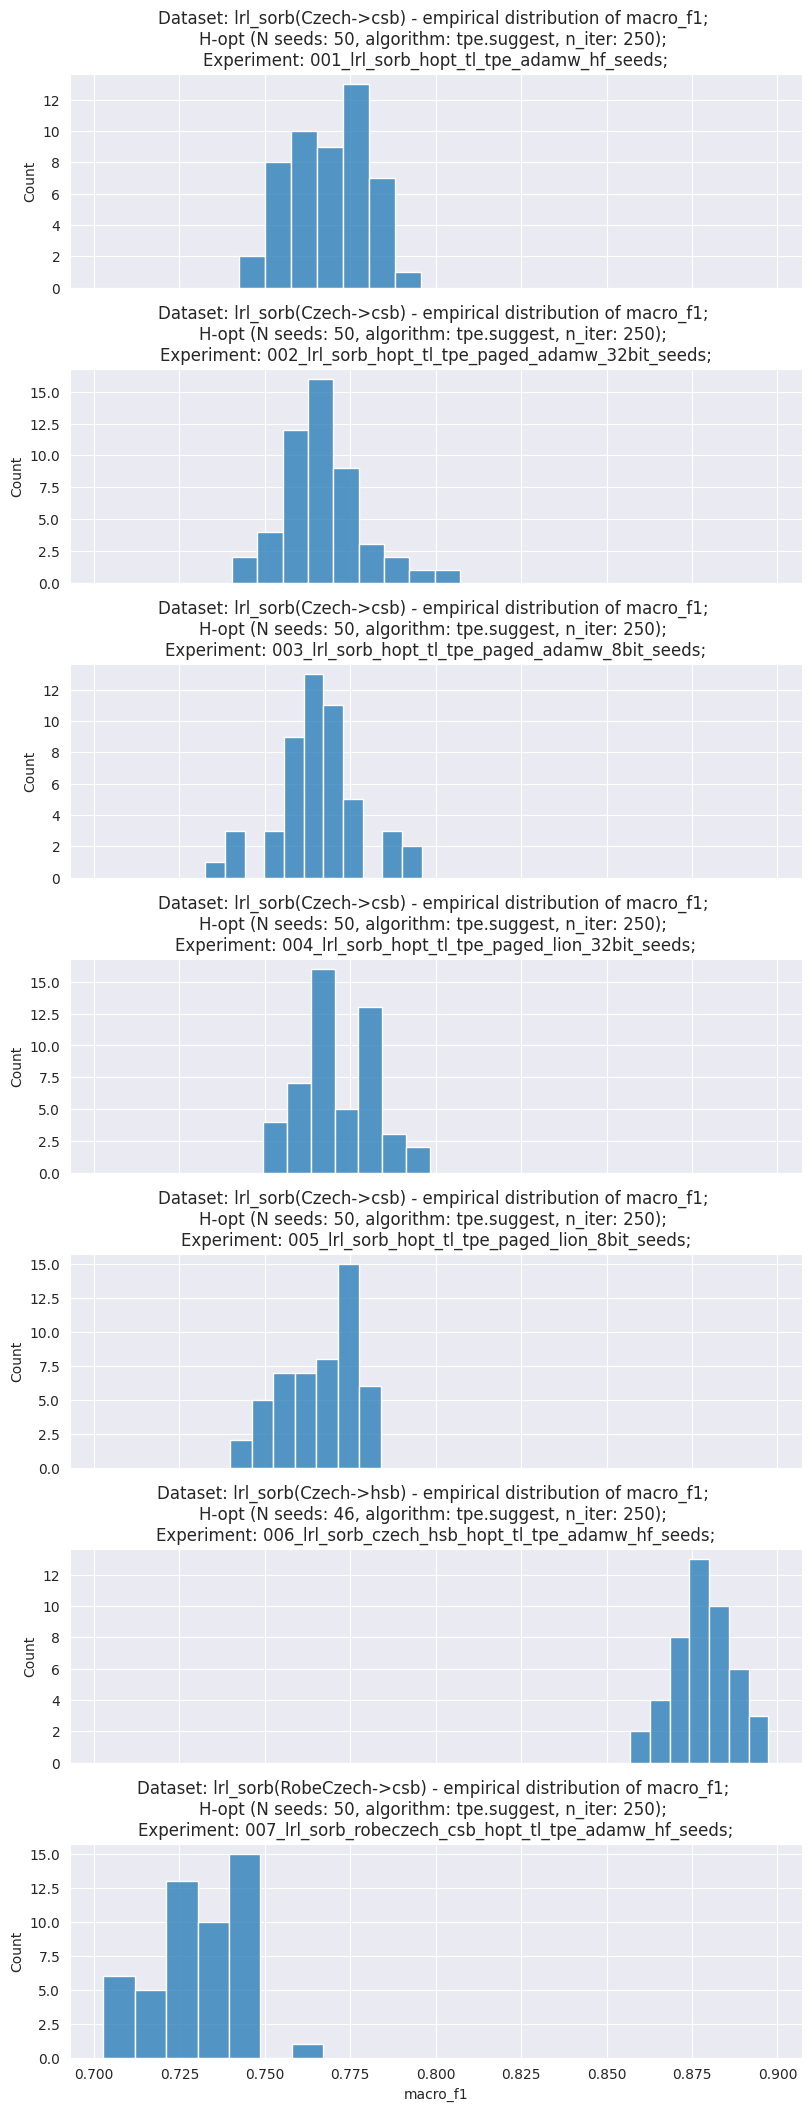

In [10]:
fig: plt.Figure

nrows = len(experiments)

fig, axs = plt.subplots(nrows=nrows, figsize=(8, nrows*3), constrained_layout=True, sharex="all")
axs = axs.flatten()

for ax, experiment in zip(axs, experiments):
    visualization.hopt_results_plot.plot_metric_hist(
        df=experiment["df_minima_latest"],
        experiment_name=experiment["name"],
        dataset_name=experiment["dataset+model"],
        hopt_algorithm_name="tpe.suggest",
        n_iter=250,
        metric_name="macro_f1",
        result_col="macro_f1",
        ax=ax
    )

In [15]:
for experiment in experiments:
    print(f"Saving {experiment['name']} ...")
    metric_values = pd.DataFrame(
        [{"omniopt_seed": seed, "macro_f1": info["scores"]["macro_f1"]}
         for seed, info in experiment["seed_to_result"].items()]
    )
    metric_values.to_csv(
        path_experiments / experiment["name"] / "data" / "processed" / "hopt" / "metric_values.csv",
        index=False
    )
    experiment["df_distribution"] = metric_values
    

Saving 001_lrl_sorb_hopt_tl_tpe_adamw_hf_seeds ...
Saving 002_lrl_sorb_hopt_tl_tpe_paged_adamw_32bit_seeds ...
Saving 003_lrl_sorb_hopt_tl_tpe_paged_adamw_8bit_seeds ...
Saving 004_lrl_sorb_hopt_tl_tpe_paged_lion_32bit_seeds ...
Saving 005_lrl_sorb_hopt_tl_tpe_paged_lion_8bit_seeds ...
Saving 006_lrl_sorb_czech_hsb_hopt_tl_tpe_adamw_hf_seeds ...


In [13]:
for experiment in experiments:
    print(experiment["name"])
    display(experiment["df_minima_latest"].loc[experiment["df_minima_latest"]["RESULT"].idxmin()])

001_lrl_sorb_hopt_tl_tpe_adamw_hf_seeds


time                                              2023-09-07 12:29:15
0                                                                 0.0
BL                                                               80.0
BO                                                               56.0
BP                                                               49.0
IO                                                               88.0
IP                                                               53.0
RESULT                                                       0.279373
endtime                                             1694089811.482013
hostname                                                  taurusi8003
learning_rate                                                0.000192
logfile_path        /beegfs/.global0/ws/s4610340-isml/lrl_sorb/exp...
loss                                                         0.279373
num_train_epochs                                                 16.0
starttime           

002_lrl_sorb_hopt_tl_tpe_paged_adamw_32bit_seeds


time                                              2023-09-07 11:03:41
0                                                                 0.0
BL                                                               80.0
BO                                                               56.0
BP                                                               49.0
IO                                                               88.0
IP                                                               53.0
RESULT                                                       0.284211
endtime                                             1694084680.118073
hostname                                                  taurusi8028
learning_rate                                                0.000109
logfile_path        /beegfs/.global0/ws/s4610340-isml/lrl_sorb/exp...
loss                                                         0.284211
num_train_epochs                                                 17.0
starttime           

003_lrl_sorb_hopt_tl_tpe_paged_adamw_8bit_seeds


...

time                                              2023-09-08 08:25:56
0                                                                 0.0
BL                                                               80.0
BO                                                               56.0
BP                                                               49.0
IO                                                               88.0
IP                                                               53.0
RESULT                                                       0.274725
endtime                                             1694161612.408382
hostname                                                  taurusi8028
learning_rate                                                 0.00019
logfile_path        /beegfs/.global0/ws/s4610340-isml/lrl_sorb/exp...
loss                                                         0.274725
num_train_epochs                                                 16.0
starttime           

005_lrl_sorb_hopt_tl_tpe_paged_lion_8bit_seeds


time                                              2023-09-08 16:28:06
0                                                                 0.0
BL                                                               80.0
BO                                                               56.0
BP                                                               49.0
IO                                                               88.0
IP                                                               53.0
RESULT                                                        0.27551
endtime                                             1694190542.128461
hostname                                                  taurusi8015
learning_rate                                                0.000121
logfile_path        /beegfs/.global0/ws/s4610340-isml/lrl_sorb/exp...
loss                                                          0.27551
num_train_epochs                                                 14.0
starttime           

006_lrl_sorb_czech_hsb_hopt_tl_tpe_adamw_hf_seeds


time                                              2023-09-14 11:08:31
0                                                                 0.0
BL                                                               81.0
BO                                                               51.0
BP                                                               49.0
IO                                                               95.0
IP                                                              100.0
RESULT                                                       0.188011
endtime                                             1694689762.999591
hostname                                                  taurusi8012
learning_rate                                                0.000181
logfile_path        /beegfs/.global0/ws/s4610340-isml/lrl_sorb/exp...
loss                                                         0.188011
num_train_epochs                                                 13.0
starttime           